In [1]:
# ---- Device: must run before anything imports jax ----
from frbayes.devices import use_device
use_device("auto")      # "auto" | "gpu" | "cpu"  (restart the kernel to switch)

import os
# os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false") # If sharing GPU with other processes
os.environ.setdefault("XLA_PYTHON_CLIENT_MEM_FRACTION", "0.2") # If not set, JAX automatically grabs 75% of the GPU's total memory, which can be excessive
# os.environ["XLA_FLAGS"] = (os.environ.get("XLA_FLAGS", "") + " --xla_gpu_deterministic_ops=true").strip() #force deterministic computation on GPU
import jax, numpyro
import jax.numpy as jnp
import numpy as np
print("JAX:", jax.__version__)
print(jax.default_backend())   # 'gpu' or 'cpu': where JAX runs things by default
print(jax.devices())           # e.g. [CudaDevice(id=0)] for the GPU, or 8 CpuDevices
print("local device count:", jax.local_device_count())

import matplotlib.pyplot as plt
import arviz as az
import arviz_base
import arviz_plots as azp
from frbayes.postprocess import pointwise_log_lik, combine_chains, order_pulses

import numpyro.distributions as dist

from frbayes.model import (
    setup_model,
    running_power_law_log_sed,
)
from frbayes.data import (
    prepare_burst,
)
from frbayes.run import (
    run_maxL,
    run_maxL_iterative,
    run_NUTS,
    set_priors,
)
from frbayes.results import (
    save_run,
)
from frbayes.plotting import (
    plot_burst_TD,
    plot_burst_FD,
    model_from_draw,
    plot_fit_TD,
)

from pathlib import Path

FRBayes: running on the GPU
JAX: 0.11.2
gpu
[CudaDevice(id=0)]
local device count: 1


In [2]:
# from numpyro.contrib.nested_sampling import NestedSampler   # jaxns switches JAX to float64 on this import

758 good channels -> 47 blocks of 16 (6 dropped); block span median 7.422 MHz, max 37.500 MHz
noise estimated from 796 of 3983 time bins (first 20% of the segment)
Fourier truncation: keeping 30 of 1992 bins (up to 0.7 kHz of 48.8 kHz)
reference frequency 549.5 MHz (channels weighted by their signal in 8 significant box(es); weighted mean 576.5 MHz)
Fourier truncation, estimated with the box search of the data: SNR in its 8 significant box(es) 277.5 with the kept bins, 316.2 with every bin (self-noise raises the second too)
burst data shape = (47, 30)
rebaseline: each channel's noise-window mean subtracted, for display only.


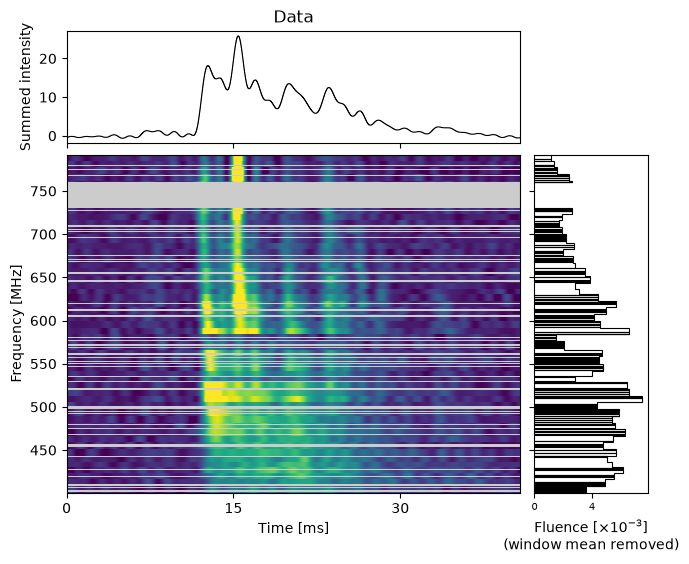

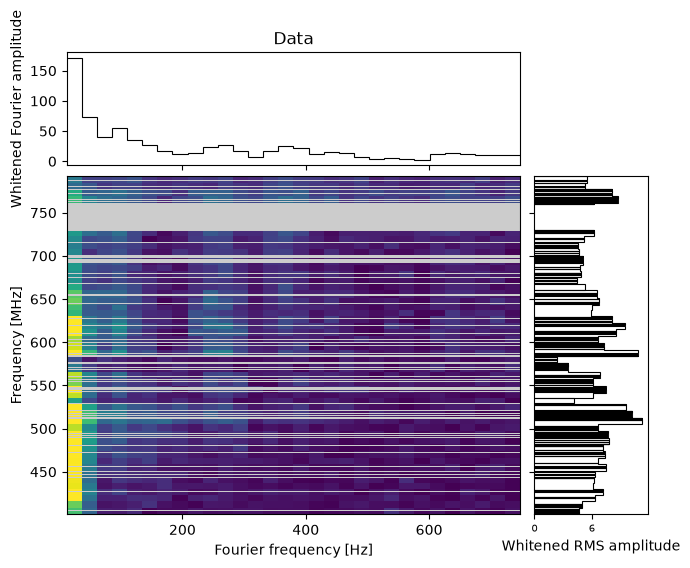

In [4]:
PROJECT  = Path("/arc/home/hsiegel/FRBayes")

# event_id = "22310619_BB" #Multi-pulse, 4 pulses
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# "22310619_BB"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

event_id = "27687783_BB" #Multi-pulse, many
data_path = PROJECT / "data" / f"event_{event_id}.npz"
burst = prepare_burst(
    path=data_path,
    n_avg=16,                # frequency channels averaged per block
    fd_downsample=64,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

# event_id = "23438043_BB" # Single-pulse, Narrow SED with scatter
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "22154974_BB" # Single-pulse, Broadband with scatter
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# How the data were dedispersed before FRBayes; save_run refuses to save without both
dm_dedispersion = None          # pc cm^-3 (fill in)
dedispersion_ref_freq = None    # MHz the channels were aligned to; np.inf for infinite frequency (fill in)

out_path  = PROJECT / "runs" / f"event_{event_id}.nc"
out_path.parent.mkdir(parents=True, exist_ok=True)     # create runs/ if it doesn't exist

print("burst data shape =",burst.data_fd.shape)
plot_burst_TD(burst);                                          # data, in time
plot_burst_FD(burst);                                          # data, in Fourier space

# maxL itfit

In [5]:
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,                   # 0 means coherently dedispersed: only the fitted residual DM smears within a channel
    "freq_members": burst.freq_members,     # raw channels averaged into each channel, for the smearing
    "raw_channel_width": burst.raw_dnu,     # width of one raw channel (MHz)
    "det_response": 1.0,                    # beam response, set to 1 if not used
}
single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=running_power_law_log_sed,
    fourier_freqs=burst.fourier_freqs,
)

group_chains: 64 chains -> 1 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63], largest R-hat within 1.057
64 chains x 200 draws


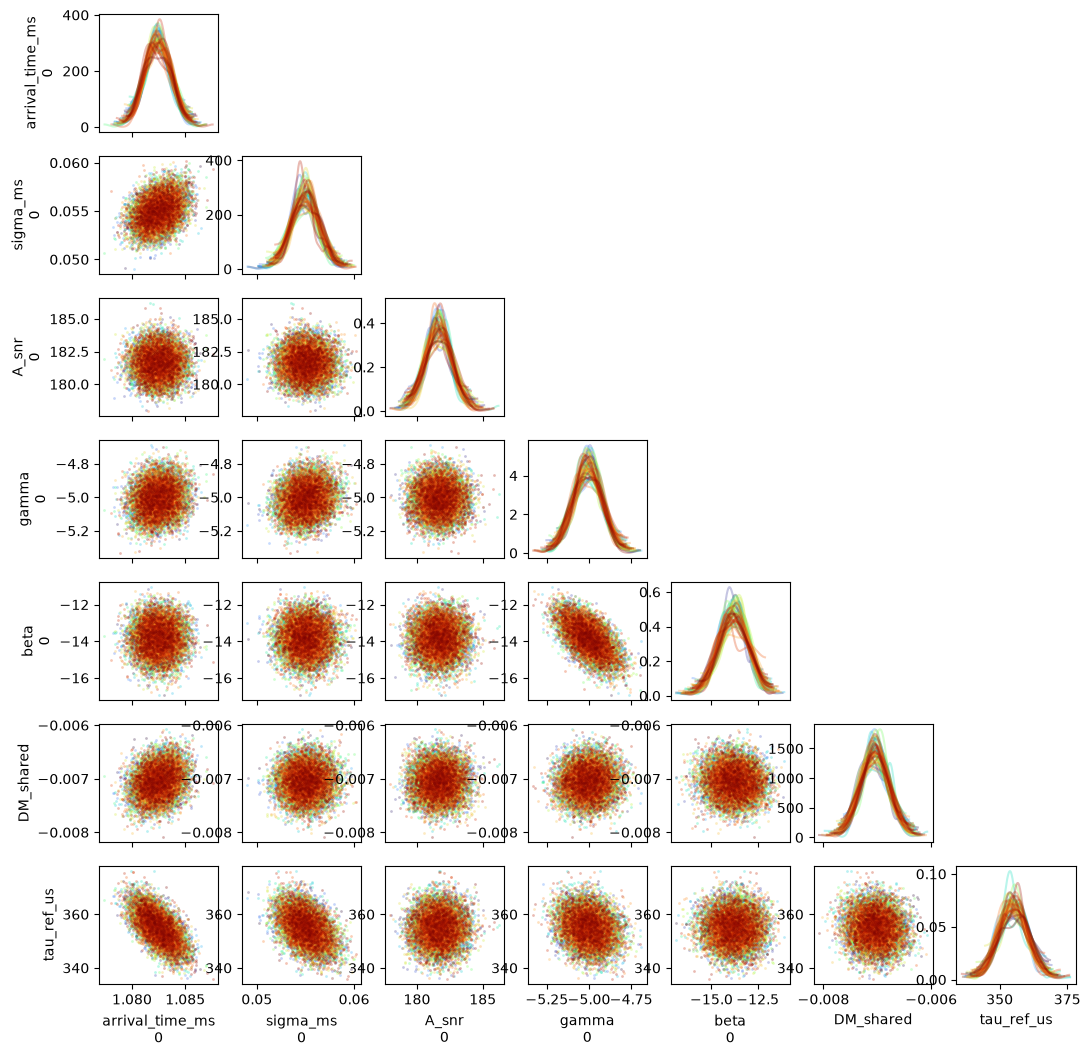

In [22]:
from frbayes.postprocess import group_chains, PAIR_SITES
from matplotlib.colors import to_hex

run = mcmc                                 # a run_fit result (e.g. started with maxL_start=res_ml)
PULSE = 0                                  # which pulse to plot (0 = earliest)

# Every chain is kept, assuming the posterior has one mode; each draw's pulses are ordered by arrival time
n = run.n_pulses
s = order_pulses({k: np.asarray(v) for k, v in run.get_samples(group_by_chain=True).items()}, verbose=False)

# Check of that assumption: chains that disagree (pairwise R-hat above 1.1) are printed as separate modes
group_chains(s, pointwise_log_lik(burst, single_pulse_fn, s, thin=1))

# All chains, in readable units, keeping the chain axis for R-hat and ESS
units = {"mean_arrival_time": ("arrival_time_ms", 1e3), "sigma": ("sigma_ms", 1e3), "tau_ref": ("tau_ref_us", 1e6)}
data, dims = {}, {}
for k, v in s.items():
    v = np.asarray(v, dtype=float)
    if (not k.endswith("_shared") and f"{k}_shared" in s) or k in PAIR_SITES:
        continue                           # copies of shared parameters, and pair sites like toa_separation
    name, unit = units.get(k.removesuffix("_shared"), (k, 1.0))
    data[name] = v * unit
    if v.ndim == 3:
        dims[name] = ["pulse"]
dt = az.from_dict({"posterior": data}, dims=dims, coords={"pulse": np.arange(n)})
n_chains = dt.posterior.sizes["chain"]
print(f"{n_chains} chains x {dt.posterior.sizes['draw']} draws")

# Corner plot of one pulse with the shared parameters, one colour per chain
pulse_vars = [v for v in ["arrival_time_ms", "sigma_ms", "A_snr", "gamma", "beta", "delta"] if v in dt.posterior]
shared_vars = [v for v in ["DM_shared", "tau_ref_us"] if v in dt.posterior]
names = pulse_vars + shared_vars
arviz_base.rcParams["plot.max_subplots"] = 300
azp.plot_pair(dt, var_names=names, coords={"pulse": [PULSE]}, marginal=True, triangle="lower",
              aes={"color": ["chain"]}, aes_by_visuals={"scatter": ["color"], "dist": ["color"]},
              color=[to_hex(c) for c in plt.cm.turbo(np.linspace(0, 1, n_chains))],
              visuals={"scatter": {"alpha": 0.3, "size": 4}, "dist": {"alpha": 0.3}},
              figure_kwargs={"figsize": (1.8 * len(names), 1.8 * len(names))})
plt.show()

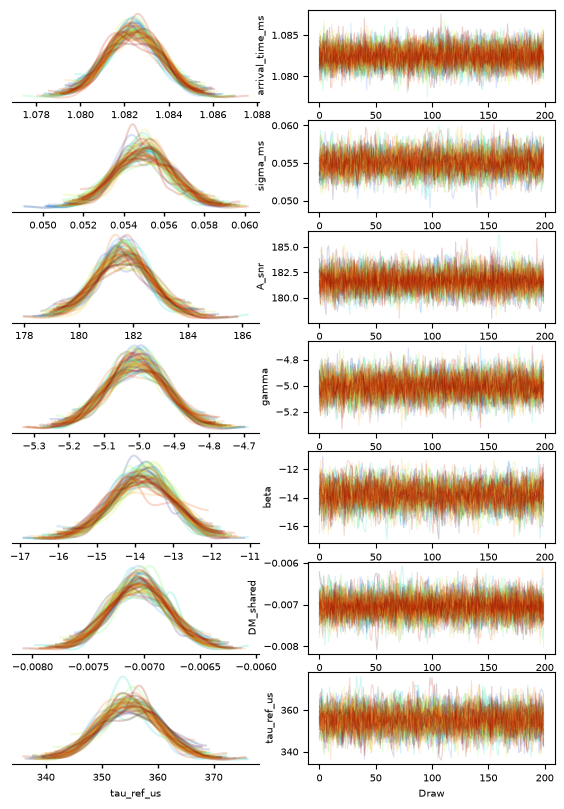

In [23]:
# Trace of every chain, one colour per chain: chains sampling the same mode overlap, separate ones sit apart
from matplotlib.colors import to_hex
n_chains = dt.posterior.sizes["chain"]
with plt.rc_context({"font.size": 7}):
    azp.plot_trace_dist(dt, var_names=names, coords={"pulse": [PULSE]}, compact=True,
                        aes={"color": ["chain"]}, aes_by_visuals={"trace": ["color"], "dist": ["color"]},
                        color=[to_hex(c) for c in plt.cm.turbo(np.linspace(0, 1, n_chains))],
                        visuals={"trace": {"alpha": 0.2, "linewidth": 0.8}, "dist": {"alpha": 0.2}},
                        figure_kwargs={"figsize": (7, 1.4 * len(names))})
    plt.show()

In [24]:
az.summary(dt, kind="all")

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.0012529,1.41e-05,0.0012,0.0013,10101,9056,1.01,1.4e-07,1.3e-07
A_snr[0],181.64,1,180,180,15163,9435,1.01,0.0082,0.0098
DM_shared,-0.007046,0.00026,-0.0075,-0.0066,14625,9552,1.01,2.2e-06,2.4e-06
beta[0],-13.81,0.8,-15,-13,8924,8751,1.00,0.0084,0.0069
gamma[0],-5.007,0.084,-5.1,-4.9,11425,11107,1.00,0.00079,0.00062
log_sed_peak[0],0.3756,0.016,0.35,0.4,9567,9885,1.00,0.00016,0.00013
arrival_time_ms[0],1.08244,0.00122,1.1,1.1,12212,10653,1.00,1.1e-05,9.7e-06
sigma_ms[0],0.055,0.00141,0.053,0.057,8972,8263,1.01,1.5e-05,1.2e-05
snr_opt[0],9.96e+04,1.46e+03,97000,100000,9439,9925,1.00,15,12
tau_ref_us,355.1,5.46,350,360,9098,8785,1.00,0.057,0.048


# Peak GPU Memory Usage

Run this cell to see the peak memory usage of the computing devices (GPU, CPU). This should give you a sense of how many analyses could be run in parallel on one device.

In [25]:
stats = jax.devices()[0].memory_stats()
print(f"peak {stats['peak_bytes_in_use'] / 1e9:.2f} GB of {stats['bytes_limit'] / 1e9:.2f} GB")

peak 0.14 GB of 2.31 GB
